In [2]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader

ROOT = Path(r"E:\Rasengan\Cloud-Removal")
MANIFEST = ROOT / "data" / "diffcr_patches" / "manifest.csv"
CHECKPOINT_PATH = ROOT / "checkpoints" / "best_model.pth"
OUTPUT_DIR = ROOT / "evaluation"

sys.path.insert(0, str(ROOT))

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
from src.model import DiffCRModel
from src.diffusion import Diffusion
from src.sampler import DiffusionSampler

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

model = DiffCRModel().to(DEVICE)
model.load_state_dict(checkpoint["model"])
model.eval()

diffusion = Diffusion()
sampler = DiffusionSampler(diffusion)

print("Checkpoint loaded successfully")
print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])
print("Device:", DEVICE)

Checkpoint loaded successfully
Best epoch: 7
Best validation loss: 0.05409072526691175
Device: cuda


In [4]:
from src.train import SatellitePatchDataset

test_dataset = SatellitePatchDataset(
    manifest_path=str(MANIFEST),
    split="test"
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

print("Test patches:", len(test_dataset))
print("Test batches:", len(test_loader))

Device: cuda
train: 51,414 patches
val: 10,442 patches
test: 13,695 patches
Test patches: 13695
Test batches: 3424


In [5]:
train_dataset = SatellitePatchDataset(
    manifest_path=str(MANIFEST),
    split="train"
)

val_dataset = SatellitePatchDataset(
    manifest_path=str(MANIFEST),
    split="val"
)

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

print("Training patches:", len(train_dataset))
print("Validation patches:", len(val_dataset))
print("Test patches:", len(test_dataset))

train: 51,414 patches
val: 10,442 patches
Training patches: 51414
Validation patches: 10442
Test patches: 13695


## Inspect one batch from each split

In [6]:
def inspect_batch(loader, split_name):
    cloudy, clear = next(iter(loader))

    print(f"\n{split_name} split")
    print("-" * 35)
    print("Cloudy shape:", cloudy.shape)
    print("Clear shape:", clear.shape)
    print("Cloudy range:", cloudy.min().item(), "to", cloudy.max().item())
    print("Clear range:", clear.min().item(), "to", clear.max().item())

inspect_batch(train_loader, "Training")
inspect_batch(val_loader, "Validation")
inspect_batch(test_loader, "Test")


Training split
-----------------------------------
Cloudy shape: torch.Size([4, 3, 256, 256])
Clear shape: torch.Size([4, 3, 256, 256])
Cloudy range: -0.8201368451118469 to -0.006842613220214844
Clear range: -0.8514174222946167 to -0.30596286058425903

Validation split
-----------------------------------
Cloudy shape: torch.Size([4, 3, 256, 256])
Clear shape: torch.Size([4, 3, 256, 256])
Cloudy range: -0.04398828744888306 to 0.8455523252487183
Clear range: -0.859237551689148 to 0.23753666877746582

Test split
-----------------------------------
Cloudy shape: torch.Size([4, 3, 256, 256])
Clear shape: torch.Size([4, 3, 256, 256])
Cloudy range: -0.6031280755996704 to 0.8885630369186401
Clear range: -0.9452590346336365 to -0.3352883458137512


## Visualize cloudy input vs. clear ground truth

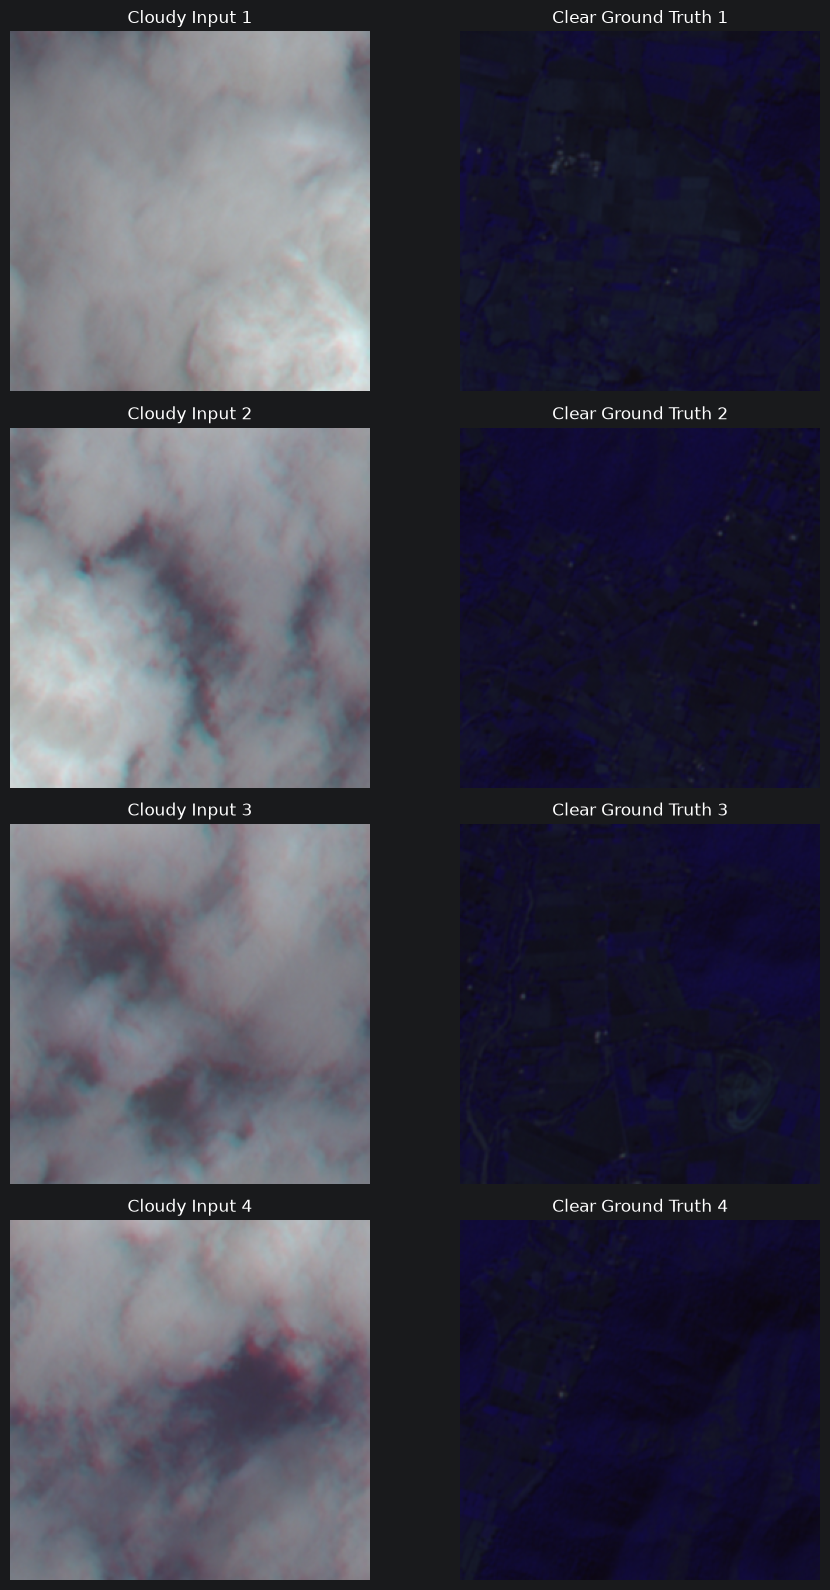

In [7]:
cloudy, clear = next(iter(test_loader))

def to_display(image):
    image = image.detach().cpu().permute(1, 2, 0).numpy()
    image = (image + 1) / 2
    return np.clip(image, 0, 1)

fig, axes = plt.subplots(4, 2, figsize=(10, 16))

for i in range(4):
    axes[i, 0].imshow(to_display(cloudy[i]))
    axes[i, 0].set_title(f"Cloudy Input {i + 1}")

    axes[i, 1].imshow(to_display(clear[i]))
    axes[i, 1].set_title(f"Clear Ground Truth {i + 1}")

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

## Inspect the inference sampler

In [8]:
import inspect

print("DIFFUSION CONFIGURATION")
print("-" * 50)
print(inspect.getsource(Diffusion.__init__))
print(inspect.getsource(Diffusion.q_sample))

print("\nSAMPLER IMPLEMENTATION")
print("-" * 50)
print(inspect.getsource(DiffusionSampler.sample))

DIFFUSION CONFIGURATION
--------------------------------------------------
    def __init__(
        self,
        timesteps=1000,
        beta_start=1e-4,
        beta_end=0.02,
        device=None,
    ):
        self.timesteps = timesteps
        self.device = device or torch.device(
            "cuda" if torch.cuda.is_available() else "cpu"
        )

        self.betas = torch.linspace(
            beta_start, beta_end, timesteps
        ).to(self.device)

        self.alphas = 1.0 - self.betas
        self.alpha_bars = torch.cumprod(self.alphas, dim=0)

        self.sqrt_alpha_bars = torch.sqrt(self.alpha_bars)
        self.sqrt_one_minus_alpha_bars = torch.sqrt(
            1.0 - self.alpha_bars
        )

    def q_sample(self, x_start, timesteps, noise=None):
        if noise is None:
            noise = torch.randn_like(x_start)

        sqrt_alpha_bar = self._extract(
            self.sqrt_alpha_bars, timesteps, x_start.shape
        )

        sqrt_one_minus_alpha_bar = sel

## Generate a small reconstruction preview

In [9]:
cloudy, clear = next(iter(test_loader))

cloudy = cloudy.to(DEVICE)
clear = clear.to(DEVICE)

with torch.no_grad():
    reconstructed = sampler.sample(
        model,
        cloudy,
        sampling_steps=20
    )

print("Cloudy shape:", cloudy.shape)
print("Reconstructed shape:", reconstructed.shape)
print("Ground truth shape:", clear.shape)
print(
    "Reconstruction range:",
    reconstructed.min().item(),
    "to",
    reconstructed.max().item()
)

Cloudy shape: torch.Size([4, 3, 256, 256])
Reconstructed shape: torch.Size([4, 3, 256, 256])
Ground truth shape: torch.Size([4, 3, 256, 256])
Reconstruction range: -0.9356178045272827 to -0.43570268154144287


## Compare cloudy, reconstructed, and ground truth

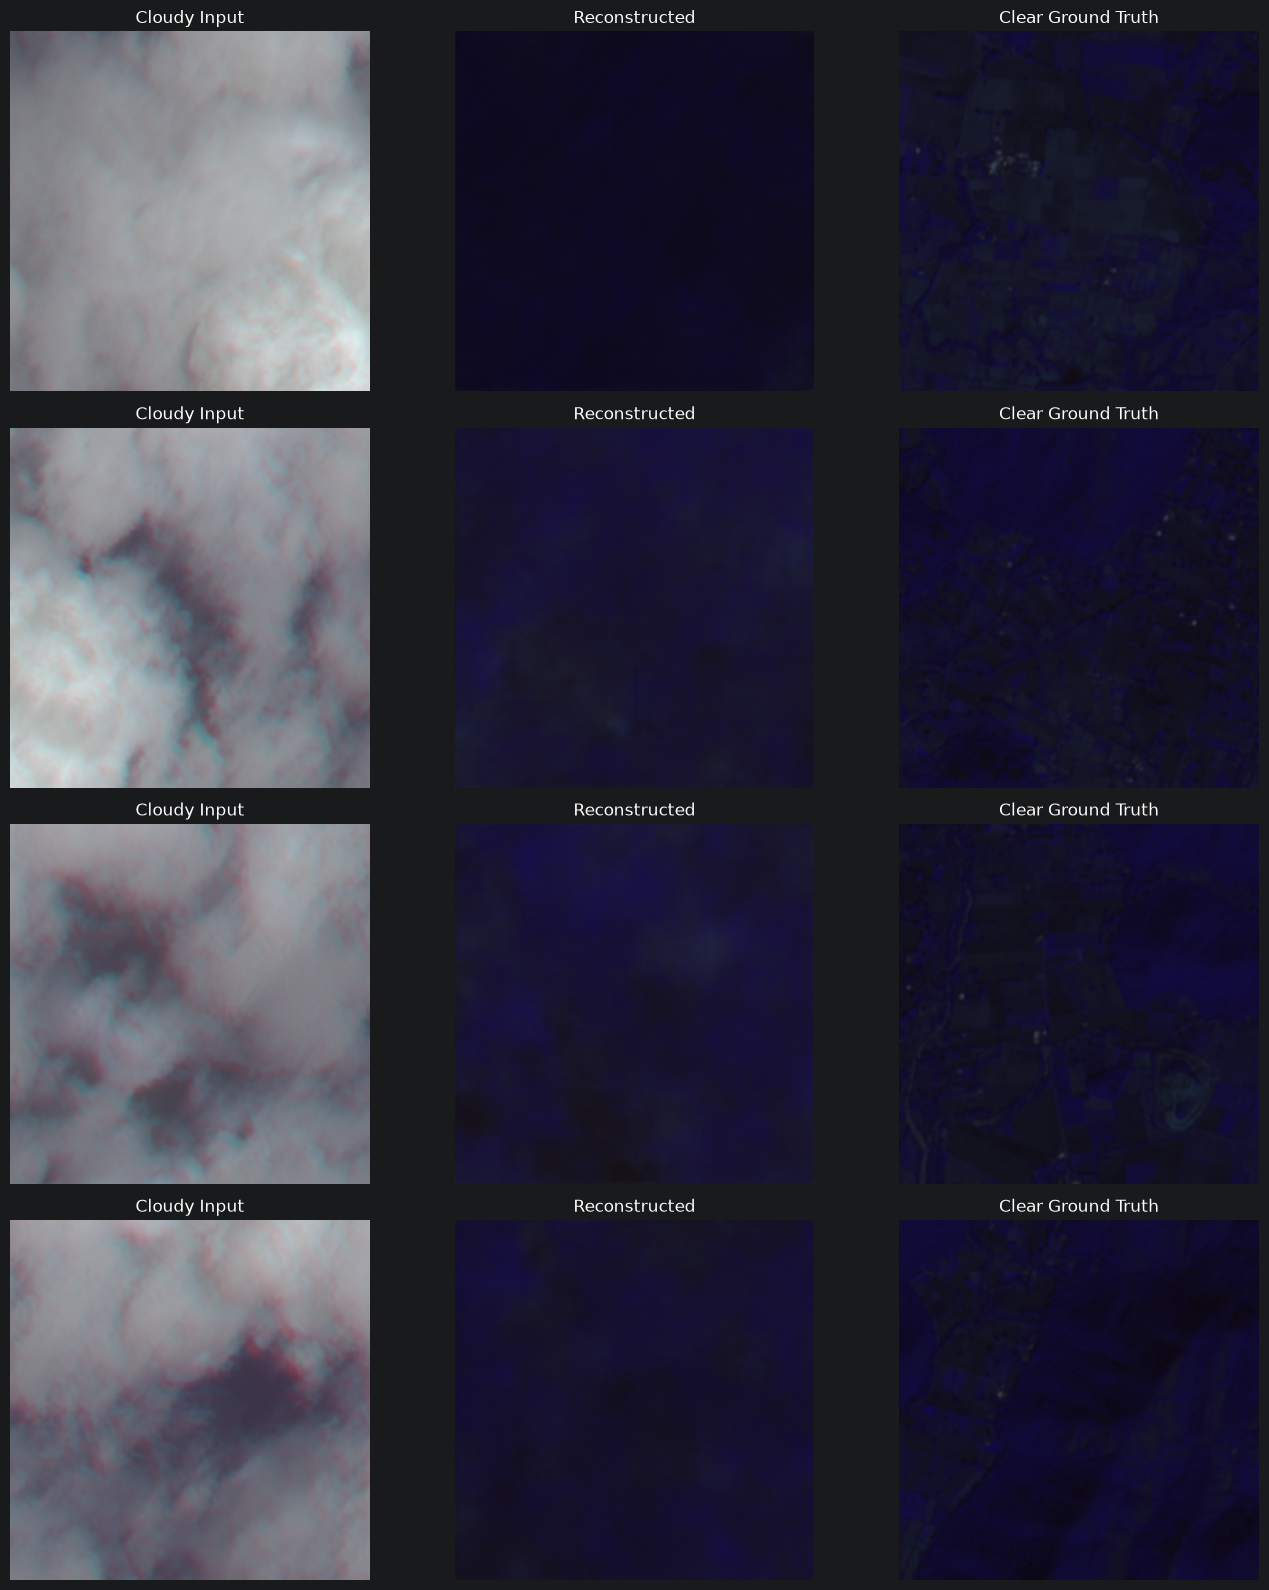

In [10]:
fig, axes = plt.subplots(4, 3, figsize=(14, 16))

for i in range(4):
    axes[i, 0].imshow(to_display(cloudy[i]))
    axes[i, 0].set_title("Cloudy Input")

    axes[i, 1].imshow(to_display(reconstructed[i]))
    axes[i, 1].set_title("Reconstructed")

    axes[i, 2].imshow(to_display(clear[i]))
    axes[i, 2].set_title("Clear Ground Truth")

    for j in range(3):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

## Inspect the actual inference algorithm

In [11]:
import inspect

print("=" * 60)
print("DIFFUSION INITIALIZATION")
print("=" * 60)
print(inspect.getsource(Diffusion.__init__))

print("\n" + "=" * 60)
print("FORWARD DIFFUSION")
print("=" * 60)
print(inspect.getsource(Diffusion.q_sample))

print("\n" + "=" * 60)
print("INFERENCE SAMPLER")
print("=" * 60)
print(inspect.getsource(DiffusionSampler.sample))

DIFFUSION INITIALIZATION
    def __init__(
        self,
        timesteps=1000,
        beta_start=1e-4,
        beta_end=0.02,
        device=None,
    ):
        self.timesteps = timesteps
        self.device = device or torch.device(
            "cuda" if torch.cuda.is_available() else "cpu"
        )

        self.betas = torch.linspace(
            beta_start, beta_end, timesteps
        ).to(self.device)

        self.alphas = 1.0 - self.betas
        self.alpha_bars = torch.cumprod(self.alphas, dim=0)

        self.sqrt_alpha_bars = torch.sqrt(self.alpha_bars)
        self.sqrt_one_minus_alpha_bars = torch.sqrt(
            1.0 - self.alpha_bars
        )


FORWARD DIFFUSION
    def q_sample(self, x_start, timesteps, noise=None):
        if noise is None:
            noise = torch.randn_like(x_start)

        sqrt_alpha_bar = self._extract(
            self.sqrt_alpha_bars, timesteps, x_start.shape
        )

        sqrt_one_minus_alpha_bar = self._extract(
            self.sq

## Test direct prediction at timestep 0

In [12]:
cloudy, clear = next(iter(test_loader))

cloudy = cloudy.to(DEVICE)
clear = clear.to(DEVICE)

with torch.no_grad():
    timesteps = torch.zeros(
        cloudy.shape[0],
        device=DEVICE,
        dtype=torch.long
    )

    noisy_clear = diffusion.q_sample(clear, timesteps)

    model_input = torch.cat([cloudy, noisy_clear], dim=1)
    direct_prediction = model(model_input, timesteps)

print("Ground truth range:",
      clear.min().item(), "to", clear.max().item())

print("Noisy clear range:",
      noisy_clear.min().item(), "to", noisy_clear.max().item())

print("Direct prediction range:",
      direct_prediction.min().item(), "to", direct_prediction.max().item())

print("Direct prediction MAE:",
      torch.mean(torch.abs(direct_prediction - clear)).item())

Ground truth range: -0.9452590346336365 to -0.3352883458137512
Noisy clear range: -0.9707009792327881 to -0.331576406955719
Direct prediction range: -0.9633526802062988 to -0.423359215259552
Direct prediction MAE: 0.017339935526251793


## Test prediction with random noise

In [13]:
cloudy, clear = next(iter(test_loader))

cloudy = cloudy.to(DEVICE)
clear = clear.to(DEVICE)

random_noise = torch.randn_like(cloudy)

with torch.no_grad():
    timesteps = torch.zeros(
        cloudy.shape[0],
        device=DEVICE,
        dtype=torch.long
    )

    model_input = torch.cat([cloudy, random_noise], dim=1)
    random_noise_prediction = model(model_input, timesteps)

print("Ground truth range:",
      clear.min().item(), "to", clear.max().item())

print("Prediction range:",
      random_noise_prediction.min().item(),
      "to", random_noise_prediction.max().item())

print("Prediction MAE:",
      torch.mean(torch.abs(random_noise_prediction - clear)).item())

Ground truth range: -0.9452590346336365 to -0.3352883458137512
Prediction range: -0.6186014413833618 to 0.5399041175842285
Prediction MAE: 0.8101227283477783


In [14]:
print(model)

DiffCRModel(
  (intro): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (cond_intro): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (ending): Conv2d(32, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (time_mlp): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): SiLU()
    (2): Linear(in_features=256, out_features=256, bias=True)
  )
  (encoders): ModuleList(
    (0): EmbedSequential(
      (0): NAFBlock(
        (norm1): LayerNorm2d()
        (conv1): Conv2d(32, 64, kernel_size=(1, 1), stride=(1, 1))
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=64)
        (gate): SimpleGate()
        (attention_avg): Sequential(
          (0): AdaptiveAvgPool2d(output_size=1)
          (1): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1))
        )
        (attention_max): Sequential(
          (0): AdaptiveMaxPool2d(output_size=1)
          (1): Conv2d(16, 16, kernel_size=(1,

In [15]:
import inspect

print("=" * 60)
print("MODEL FORWARD")
print("=" * 60)
print(inspect.getsource(DiffCRModel.forward))

print("\n" + "=" * 60)
print("TRAINING LOSS")
print("=" * 60)
print(inspect.getsource(Diffusion.training_loss))

MODEL FORWARD
    def forward(self, inp, timesteps):
        if inp.ndim != 4:
            raise ValueError("Input must have shape (B, C, H, W).")

        expected_channels = self.img_channels * 2
        if inp.shape[1] != expected_channels:
            raise ValueError(
                f"Expected {expected_channels} input channels "
                f"(cloudy + noisy target), got {inp.shape[1]}."
            )

        cloudy, noisy_target = inp.split(self.img_channels, dim=1)

        h, w = inp.shape[-2:]
        pad_h = (self.padder_size - h % self.padder_size) % self.padder_size
        pad_w = (self.padder_size - w % self.padder_size) % self.padder_size

        noisy_target = F.pad(noisy_target, (0, pad_w, 0, pad_h))
        cloudy = F.pad(cloudy, (0, pad_w, 0, pad_h))

        time_embedding = self.time_mlp(
            timestep_embedding(timesteps, dim=64)
        )

        x = self.intro(noisy_target)
        cond = self.cond_intro(cloudy)

        skips = []

        for e

In [16]:
cloudy, clear = next(iter(test_loader))

cloudy = cloudy.to(DEVICE)
clear = clear.to(DEVICE)

zero_target = torch.zeros_like(cloudy)

with torch.no_grad():
    timesteps = torch.zeros(
        cloudy.shape[0],
        device=DEVICE,
        dtype=torch.long
    )

    model_input = torch.cat([cloudy, zero_target], dim=1)
    zero_input_prediction = model(model_input, timesteps)

print("Prediction range:",
      zero_input_prediction.min().item(),
      "to",
      zero_input_prediction.max().item())

print("MAE (diagnostic only):",
      torch.mean(torch.abs(zero_input_prediction - clear)).item())

Prediction range: -0.24885296821594238 to 0.053340844810009
MAE (diagnostic only): 0.7790778875350952


## Check whether the paired dataset has a normalization problem

In [18]:
def compare_dataset_statistics(loader, split_name, max_batches=2):
    cloudy_batches = []
    clear_batches = []

    for i, (cloudy, clear) in enumerate(loader):
        cloudy_batches.append(cloudy)
        clear_batches.append(clear)

        if i + 1 >= max_batches:
            break

    cloudy = torch.cat(cloudy_batches, dim=0).float()
    clear = torch.cat(clear_batches, dim=0).float()

    print(f"\n{split_name} ﷿﷿﷿﷿﷿﷿﷿﷿﷿ sampled {len(cloudy)} patches")
    print("Channel order: B2 Green, B3 Red, B4 NIR")
    print("Cloudy means:", cloudy.mean(dim=(0, 2, 3)).tolist())
    print("Clear means: ", clear.mean(dim=(0, 2, 3)).tolist())
    print("Cloudy stds: ", cloudy.std(dim=(0, 2, 3)).tolist())
    print("Clear stds:  ", clear.std(dim=(0, 2, 3)).tolist())


compare_dataset_statistics(train_loader, "TRAIN")
compare_dataset_statistics(val_loader, "VALIDATION")
compare_dataset_statistics(test_loader, "TEST")


TRAIN ﷿﷿﷿﷿﷿﷿﷿﷿﷿ sampled 8 patches
Channel order: B2 Green, B3 Red, B4 NIR
Cloudy means: [-0.2609824240207672, -0.26635971665382385, -0.18085184693336487]
Clear means:  [-0.7390270233154297, -0.7242612242698669, -0.5584456920623779]
Cloudy stds:  [0.1676383912563324, 0.17429831624031067, 0.15040245652198792]
Clear stds:   [0.028794528916478157, 0.055711597204208374, 0.08393021672964096]

VALIDATION ﷿﷿﷿﷿﷿﷿﷿﷿﷿ sampled 8 patches
Channel order: B2 Green, B3 Red, B4 NIR
Cloudy means: [0.35441064834594727, 0.364653080701828, 0.366632342338562]
Clear means:  [-0.7069635391235352, -0.6684072613716125, -0.5192404985427856]
Cloudy stds:  [0.16887661814689636, 0.17417408525943756, 0.17345893383026123]
Clear stds:   [0.03358269855380058, 0.05216921865940094, 0.06507924944162369]

TEST ﷿﷿﷿﷿﷿﷿﷿﷿﷿ sampled 8 patches
Channel order: B2 Green, B3 Red, B4 NIR
Cloudy means: [-0.045944418758153915, -0.04539511725306511, 0.033937953412532806]
Clear means:  [-0.862098753452301, -0.8806737661361694, -0.6836113

- Large cloudy﷿﷿﷿﷿﷿﷿﷿﷿﷿clear brightness difference: the cloudy and clear patches have very different means. Clouds can explain some difference, but this gap warrants investigation.
- Clear patches have unusually low variation in these samples: their standard deviations are much smaller than those of the cloudy patches. This could indicate low-contrast imagery, radiometric scaling differences, or patches dominated by uniform areas.
- Cloudy brightness varies substantially across splits: this may reflect different scenes and acquisition conditions. It does not, by itself, prove a dataset error.

In [19]:
import inspect
from src.train import SatellitePatchDataset

print(inspect.getsource(SatellitePatchDataset))

class SatellitePatchDataset(Dataset):
    def __init__(self, manifest_path, split):
        self.manifest_path = Path(manifest_path)
        self.root = self.manifest_path.parent.parent.parent

        with open(self.manifest_path, "r", newline="", encoding="utf-8-sig") as f:
            reader = csv.DictReader(f)
            rows = list(reader)
            columns = reader.fieldnames or []

        cloudy_col = find_column(
            columns,
            ["cloudy_path", "cloudy", "input_path", "cloudy_file"],
            "cloudy image path",
        )
        clear_col = find_column(
            columns,
            ["clear_path", "clear", "target_path", "clear_file", "gt_path"],
            "clear image path",
        )
        split_col = find_column(
            columns,
            ["split", "subset", "partition"],
            "split",
        )

        split_aliases = {
            "train": {"train", "training"},
            "val": {"val", "valid", "validation"},
            "

In [20]:
import rasterio
import numpy as np

cloudy_path, clear_path = train_dataset.samples[0]

for label, relative_path in [
    ("CLOUDY", cloudy_path),
    ("CLEAR", clear_path),
]:
    path = train_dataset.resolve_path(relative_path)

    with rasterio.open(path) as src:
        image = src.read()

    print(f"\n{label}: {path}")
    print("Shape:", image.shape)
    print("Dtype:", image.dtype)

    for band in range(image.shape[0]):
        values = image[band]
        print(
            f"Band {band + 1}: "
            f"min={values.min()}, "
            f"max={values.max()}, "
            f"mean={values.mean():.2f}, "
            f"std={values.std():.2f}"
        )


CLOUDY: E:\Rasengan\Cloud-Removal\data\diffcr_patches\cloudy\chennai1\r0_c10240.tif
Shape: (3, 256, 256)
Dtype: uint16
Band 1: min=115, max=375, mean=215.74, std=63.24
Band 2: min=92, max=364, mean=203.68, std=61.81
Band 3: min=160, max=413, mean=269.72, std=53.58

CLEAR: E:\Rasengan\Cloud-Removal\data\diffcr_patches\clear\chennai1\r0_c10240.tif
Shape: (3, 256, 256)
Dtype: uint16
Band 1: min=104, max=199, mean=133.09, std=14.20
Band 2: min=88, max=257, mean=141.62, std=26.69
Band 3: min=114, max=335, mean=235.48, std=26.11


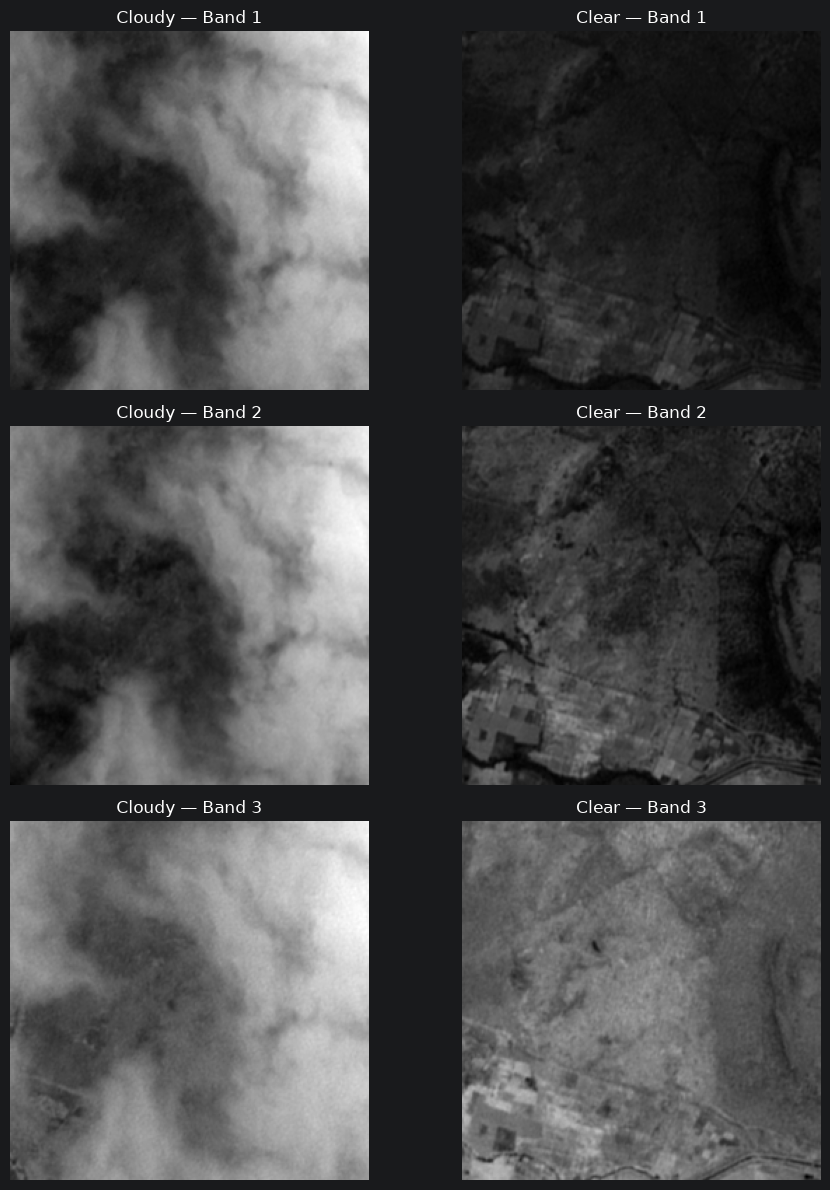

In [21]:
import matplotlib.pyplot as plt
import rasterio
import numpy as np

cloudy_path, clear_path = train_dataset.samples[0]

cloudy_path = train_dataset.resolve_path(cloudy_path)
clear_path = train_dataset.resolve_path(clear_path)

with rasterio.open(cloudy_path) as src:
    cloudy_raw = src.read().astype(np.float32)

with rasterio.open(clear_path) as src:
    clear_raw = src.read().astype(np.float32)

fig, axes = plt.subplots(3, 2, figsize=(10, 12))

for band in range(3):
    vmin = min(cloudy_raw[band].min(), clear_raw[band].min())
    vmax = max(cloudy_raw[band].max(), clear_raw[band].max())

    axes[band, 0].imshow(
        cloudy_raw[band], cmap="gray", vmin=vmin, vmax=vmax
    )
    axes[band, 0].set_title(f"Cloudy ﷿﷿﷿﷿﷿﷿﷿﷿﷿ Band {band + 1}")

    axes[band, 1].imshow(
        clear_raw[band], cmap="gray", vmin=vmin, vmax=vmax
    )
    axes[band, 1].set_title(f"Clear ﷿﷿﷿﷿﷿﷿﷿﷿﷿ Band {band + 1}")

    axes[band, 0].axis("off")
    axes[band, 1].axis("off")

plt.tight_layout()
plt.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [92.0..413.0].


Brightness threshold: 309.33
Bright-pixel fraction (not true cloud coverage): 10.04%


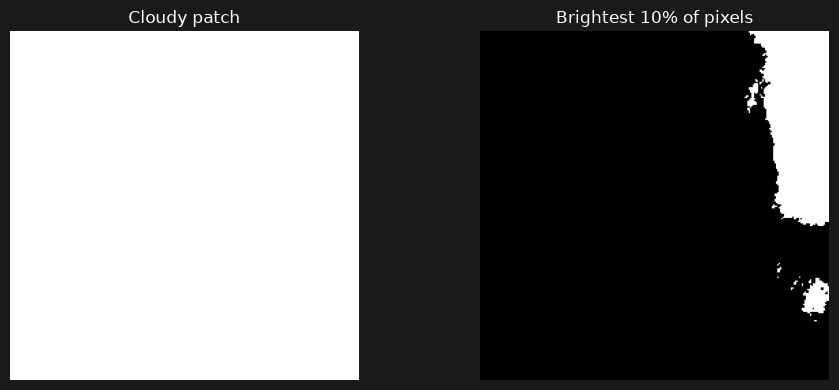

In [22]:
import numpy as np
import matplotlib.pyplot as plt

# Use the raw cloudy image loaded in the previous cell.
# Estimate cloud candidates using brightness in all three bands.
brightness = cloudy_raw.mean(axis=0)

threshold = np.percentile(brightness, 90)
cloud_candidate_mask = brightness >= threshold

print(f"Brightness threshold: {threshold:.2f}")
print(
    "Bright-pixel fraction (not true cloud coverage): "
    f"{cloud_candidate_mask.mean() * 100:.2f}%"
)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(np.moveaxis(cloudy_raw, 0, -1))
plt.title("Cloudy patch")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cloud_candidate_mask, cmap="gray")
plt.title("Brightest 10% of pixels")
plt.axis("off")

plt.tight_layout()
plt.show()

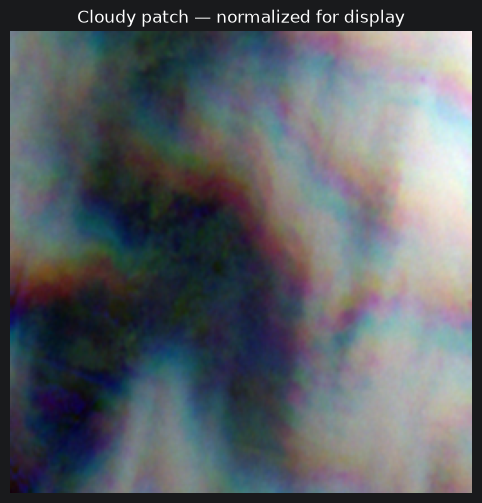

In [23]:
cloudy_display = np.moveaxis(cloudy_raw, 0, -1)

# Normalize each band independently for visualization only
cloudy_display = (
    cloudy_display - cloudy_display.min(axis=(0, 1), keepdims=True)
) / (
    np.ptp(cloudy_display, axis=(0, 1), keepdims=True) + 1e-8
)

plt.figure(figsize=(8, 6))
plt.imshow(cloudy_display)
plt.title("Cloudy patch ﷿﷿﷿﷿﷿﷿﷿﷿﷿ normalized for display")
plt.axis("off")
plt.show()

## Training-set evaluation cell

In [31]:
from src.evaluate import evaluate_metrics
import pandas as pd
import time
import torch

In [32]:
@torch.inference_mode()
def evaluate_model(model, device, loader):
    model.eval()

    totals = {"MAE": 0.0, "PSNR": 0.0, "SSIM": 0.0, "SAM": 0.0}
    processed = 0
    start_time = time.perf_counter()

    total_batches = len(loader)
    total_patches = len(loader.dataset)

    for batch_idx, (cloudy, clear) in enumerate(loader):
        cloudy = cloudy.to(device)
        clear = clear.to(device)

        prediction = sampler.sample(
            model,
            cloudy,
            sampling_steps=SAMPLING_STEPS
        )

        metrics = evaluate_metrics(prediction, clear)
        batch_size = cloudy.size(0)

        for key in totals:
            totals[key] += metrics[key] * batch_size

        processed += batch_size
        batches_done = batch_idx + 1

        if batches_done == 10 or batches_done % 100 == 0 or batches_done == total_batches:
            elapsed = time.perf_counter() - start_time
            avg_batch_time = elapsed / batches_done
            remaining_seconds = avg_batch_time * (total_batches - batches_done)

            print(
                f"TRAIN: {processed:,}/{total_patches:,} patches | "
                f"Elapsed: {elapsed / 60:.1f} min | "
                f"Estimated remaining: {remaining_seconds / 3600:.2f} hours"
            )

    results = {
        key: value / processed
        for key, value in totals.items()
    }

    print("\nTraining-set metrics:")
    display(pd.DataFrame([results]))

    return results

In [37]:
test_start = time.perf_counter()

test_metrics = evaluate_model(
    model=model,
    device=DEVICE,
    loader=test_loader
)

test_elapsed = (time.perf_counter() - test_start) / 3600

print(f"Test evaluation time: {test_elapsed:.2f} hours")

TRAIN: 40/13,695 patches | Elapsed: 0.3 min | Estimated remaining: 1.75 hours
TRAIN: 400/13,695 patches | Elapsed: 2.9 min | Estimated remaining: 1.61 hours
TRAIN: 800/13,695 patches | Elapsed: 6.2 min | Estimated remaining: 1.67 hours
TRAIN: 1,200/13,695 patches | Elapsed: 9.6 min | Estimated remaining: 1.66 hours
TRAIN: 1,600/13,695 patches | Elapsed: 12.3 min | Estimated remaining: 1.55 hours
TRAIN: 2,000/13,695 patches | Elapsed: 15.0 min | Estimated remaining: 1.46 hours
TRAIN: 2,400/13,695 patches | Elapsed: 17.7 min | Estimated remaining: 1.39 hours
TRAIN: 2,800/13,695 patches | Elapsed: 20.3 min | Estimated remaining: 1.32 hours
TRAIN: 3,200/13,695 patches | Elapsed: 23.0 min | Estimated remaining: 1.26 hours
TRAIN: 3,600/13,695 patches | Elapsed: 25.7 min | Estimated remaining: 1.20 hours
TRAIN: 4,000/13,695 patches | Elapsed: 28.4 min | Estimated remaining: 1.15 hours
TRAIN: 4,400/13,695 patches | Elapsed: 31.0 min | Estimated remaining: 1.09 hours
TRAIN: 4,800/13,695 patches

,MAE,PSNR,SSIM,SAM
0,0.034466,28.248571,0.828627,9.427482


Test evaluation time: 1.62 hours


Image shape: 256 256
Number of bands: 3


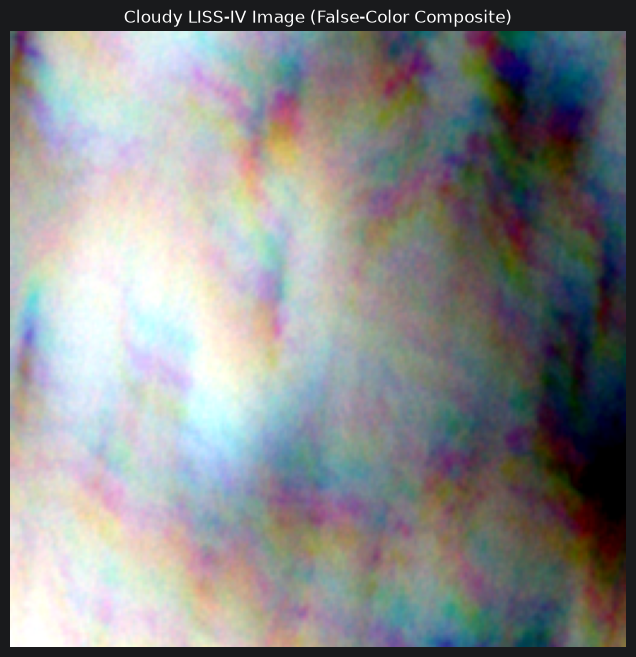

In [13]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

# Replace with your actual cloudy LISS-IV TIFF path
path = r"E:\Rasengan\Cloud-Removal\data\diffcr_patches\cloudy\nzb1\r15872_c5376.tif"

with rasterio.open(path) as src:
    print("Image shape:", src.height, src.width)
    print("Number of bands:", src.count)

    # Change these indices if your TIFF uses a different band order
    green = src.read(1).astype(np.float32)
    red   = src.read(2).astype(np.float32)
    nir   = src.read(3).astype(np.float32)

def normalize(band):
    low, high = np.percentile(band, [2, 98])
    return np.clip((band - low) / (high - low + 1e-8), 0, 1)

# False-color composite: NIR, Red, Green
image = np.stack([
    normalize(nir),
    normalize(red),
    normalize(green)
], axis=-1)

plt.figure(figsize=(10, 8))
plt.imshow(image)
plt.title("Cloudy LISS-IV Image (False-Color Composite)")
plt.axis("off")
plt.show()